# XGBoost (Extreme Gradient Boosting) — Sonobuoy Sound Detective
## Person 4: Boosting Ensemble Classifiers

**Algorithm:** XGBoost with Shrinkage & Second-Order Taylor Loss Approximation  
**Task:** 4-Class Underwater Acoustic Event Detection  
**Classes:** `vessel_like`, `marine_life`, `ambient`, `unknown`  
**Features:** 35 physics-based handcrafted acoustic descriptors  

---

### Data Split Strategy
| Split | Purpose | Size |
|-------|---------|------|
| **Train** | Model training | 64% of total |
| **Test** | Hyperparameter evaluation / early stopping | 16% of total |
| **Unseen Holdout** | Final unbiased benchmark | 20% of total |

Splits are **recording-level isolated** — no recording appears in more than one split (zero data leakage).

---

### XGBoost Theory (Review Notes)

**XGBoost** (e**X**treme **G**radient **Boost**ing) is an optimized gradient boosting framework that:

1. **Second-Order Taylor Expansion:** Approximates the loss function using both first-order gradients (*g*) and second-order Hessians (*h*), enabling more precise optimization:
   
   $$\mathcal{L}^{(t)} \approx \sum_{i=1}^{n} [g_i f_t(x_i) + \frac{1}{2} h_i f_t^2(x_i)] + \Omega(f_t)$$

2. **Regularization:** Adds L1 (`alpha`) and L2 (`lambda`) penalties to the leaf weights, controlling model complexity:
   
   $$\Omega(f) = \gamma T + \frac{1}{2} \lambda \sum_{j=1}^{T} w_j^2$$

3. **Shrinkage (Learning Rate):** Each tree's contribution is scaled by `eta` (learning rate), preventing overfitting

4. **Column Subsampling:** Randomly samples features at each split (like Random Forest) to reduce variance

5. **Built-in Handling of Missing Values:** Learns optimal default directions for missing features

**Why XGBoost for sonobuoy edge deployment:**
- Highly optimized C++ backend with minimal memory footprint
- Trees can be exported as fixed-point decision rules for microcontrollers
- Sub-millisecond inference for shallow tree ensembles
- Superior accuracy compared to simpler boosting methods


In [1]:
# ============================================================
# 1. Imports & Configuration
# ============================================================
import os
import json
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import xgboost as xgb

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, auc,
    log_loss
)
from sklearn.preprocessing import label_binarize

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep', font_scale=1.1)

# Paths
DATA_DIR   = os.path.join('.', 'data')
MODEL_DIR  = os.path.join('.', 'models')
PLOT_DIR   = os.path.join('.', 'plots')
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(PLOT_DIR, exist_ok=True)

RANDOM_STATE = 42
CLASS_NAMES  = ['vessel_like', 'marine_life', 'ambient', 'unknown']

print(f"XGBoost version: {xgb.__version__}")
print("All imports successful.")


XGBoost version: 3.4.1
All imports successful.


## 2. Data Loading & Preparation
Loading the preprocessed 35-feature sonobuoy acoustic dataset with recording-level isolated splits.

- **train.csv** — 64% of data (train portion of 80% dev set)
- **test.csv** — 16% of data (test portion of 80% dev set)
- **unseen_holdout.csv** — 20% of data (completely isolated, evaluated last)


In [2]:
# ============================================================
# 2. Load Preprocessed Data Splits
# ============================================================
df_train   = pd.read_csv(os.path.join(DATA_DIR, 'train.csv'))
df_test    = pd.read_csv(os.path.join(DATA_DIR, 'test.csv'))
df_holdout = pd.read_csv(os.path.join(DATA_DIR, 'unseen_holdout.csv'))

# Load selected feature names
with open(os.path.join(DATA_DIR, 'selected_features.json'), 'r') as f:
    feature_config = json.load(f)
FEATURE_NAMES = feature_config['selected_features']

print(f"Number of selected features: {len(FEATURE_NAMES)}")
print(f"Train: {len(df_train)} | Test: {len(df_test)} | Unseen Holdout: {len(df_holdout)}")
print(f"\nTrain class distribution:")
print(df_train['label'].value_counts())
print(f"\nTest class distribution:")
print(df_test['label'].value_counts())
print(f"\nHoldout class distribution:")
print(df_holdout['label'].value_counts())


Number of selected features: 35
Train: 545 | Test: 149 | Unseen Holdout: 169

Train class distribution:
label
ambient        168
vessel_like    161
marine_life    136
unknown         80
Name: count, dtype: int64

Test class distribution:
label
vessel_like    61
marine_life    41
unknown        35
ambient        12
Name: count, dtype: int64

Holdout class distribution:
label
vessel_like    58
marine_life    43
unknown        38
ambient        30
Name: count, dtype: int64


In [3]:
# ============================================================
# 3. Feature Matrix & Label Encoding
# ============================================================
X_train   = df_train[FEATURE_NAMES].values
X_test    = df_test[FEATURE_NAMES].values
X_holdout = df_holdout[FEATURE_NAMES].values

# Label encoding
le = LabelEncoder()
le.fit(CLASS_NAMES)
y_train   = le.transform(df_train['label'])
y_test    = le.transform(df_test['label'])
y_holdout = le.transform(df_holdout['label'])

print(f"Label mapping: {dict(zip(le.classes_, le.transform(le.classes_)))}")

# StandardScaler (fit on train only - no data leakage)
scaler = StandardScaler()
X_train_scaled   = scaler.fit_transform(X_train)
X_test_scaled    = scaler.transform(X_test)
X_holdout_scaled = scaler.transform(X_holdout)

print(f"\nX_train shape:   {X_train_scaled.shape}")
print(f"X_test shape:    {X_test_scaled.shape}")
print(f"X_holdout shape: {X_holdout_scaled.shape}")


Label mapping: {np.str_('ambient'): np.int64(0), np.str_('marine_life'): np.int64(1), np.str_('unknown'): np.int64(2), np.str_('vessel_like'): np.int64(3)}

X_train shape:   (545, 35)
X_test shape:    (149, 35)
X_holdout shape: (169, 35)


## 3. XGBoost DMatrix Construction
XGBoost uses its optimized `DMatrix` data structure internally for efficient memory layout and computation.  
We use the scikit-learn API for grid search and the native API for early stopping.


In [4]:
# ============================================================
# 4. Create XGBoost DMatrices (for native API usage)
# ============================================================
dtrain   = xgb.DMatrix(X_train_scaled,   label=y_train,   feature_names=FEATURE_NAMES)
dtest    = xgb.DMatrix(X_test_scaled,    label=y_test,    feature_names=FEATURE_NAMES)
dholdout = xgb.DMatrix(X_holdout_scaled, label=y_holdout, feature_names=FEATURE_NAMES)

print(f"DMatrix shapes:")
print(f"  Train:   {dtrain.num_row()} x {dtrain.num_col()}")
print(f"  Test:    {dtest.num_row()} x {dtest.num_col()}")
print(f"  Holdout: {dholdout.num_row()} x {dholdout.num_col()}")


DMatrix shapes:
  Train:   545 x 35
  Test:    149 x 35
  Holdout: 169 x 35


## 4. Baseline XGBoost Model
Training an initial XGBoost classifier with conservative defaults to establish a performance baseline.

**Objective:** `multi:softprob` (Multiclass softmax with probability outputs)  
**Evaluation Metric:** `mlogloss` (Multiclass Log-Loss)  
**Early stopping** is applied against the **test set** to prevent overfitting.


In [5]:
# ============================================================
# 5. Baseline XGBoost Classifier (Native API with Early Stopping)
# ============================================================
params_baseline = {
    'objective':    'multi:softprob',
    'num_class':    len(CLASS_NAMES),
    'eval_metric':  'mlogloss',
    'eta':          0.3,          # Default learning rate
    'max_depth':    6,            # Default depth
    'subsample':    1.0,
    'colsample_bytree': 1.0,
    'lambda':       1.0,          # L2 regularization
    'alpha':        0.0,          # L1 regularization
    'seed':         RANDOM_STATE,
    'verbosity':    0,
}

evals_baseline = [(dtrain, 'train'), (dtest, 'test')]

start_time = time.time()
bst_baseline = xgb.train(
    params_baseline,
    dtrain,
    num_boost_round=300,
    evals=evals_baseline,
    early_stopping_rounds=30,
    verbose_eval=50
)
train_time_baseline = time.time() - start_time

# Predictions on test set
y_prob_baseline = bst_baseline.predict(dtest)
y_pred_baseline = np.argmax(y_prob_baseline, axis=1)

print(f"\nBaseline Training time: {train_time_baseline:.4f} seconds")
print(f"Best iteration: {bst_baseline.best_iteration}")
print(f"Test accuracy: {accuracy_score(y_test, y_pred_baseline):.4f}")
print(f"Test F1 (macro): {f1_score(y_test, y_pred_baseline, average='macro'):.4f}")
print(f"\nBaseline Classification Report:")
print(classification_report(y_test, y_pred_baseline, target_names=CLASS_NAMES))


[0]	train-mlogloss:0.90901	test-mlogloss:1.02760


[50]	train-mlogloss:0.00401	test-mlogloss:0.07897


[100]	train-mlogloss:0.00331	test-mlogloss:0.07732


[112]	train-mlogloss:0.00326	test-mlogloss:0.07814



Baseline Training time: 1.1942 seconds
Best iteration: 82
Test accuracy: 0.9664
Test F1 (macro): 0.9668

Baseline Classification Report:
              precision    recall  f1-score   support

 vessel_like       1.00      1.00      1.00        12
 marine_life       0.93      0.95      0.94        41
     ambient       0.94      0.91      0.93        35
     unknown       1.00      1.00      1.00        61

    accuracy                           0.97       149
   macro avg       0.97      0.97      0.97       149
weighted avg       0.97      0.97      0.97       149



## 5. Training Progress (Loss Convergence)
Visualizing the multi-class log-loss convergence to verify proper learning behavior and early stopping.


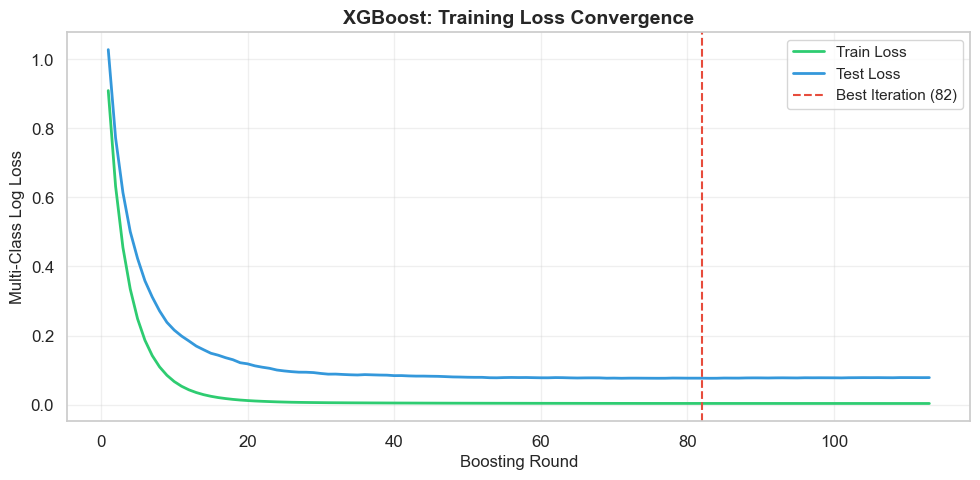

Saved: plots/xgboost_loss_convergence.png


In [6]:
# ============================================================
# 6. Training Loss Convergence
# ============================================================
# Retrain with eval results recorded
evals_result = {}
bst_track = xgb.train(
    params_baseline,
    dtrain,
    num_boost_round=300,
    evals=evals_baseline,
    evals_result=evals_result,
    early_stopping_rounds=30,
    verbose_eval=False
)

fig, ax = plt.subplots(figsize=(10, 5))
epochs = range(1, len(evals_result['train']['mlogloss']) + 1)
ax.plot(epochs, evals_result['train']['mlogloss'], label='Train Loss', linewidth=2, color='#2ecc71')
ax.plot(epochs, evals_result['test']['mlogloss'],  label='Test Loss',  linewidth=2, color='#3498db')

# Mark best iteration
best_iter = bst_track.best_iteration
ax.axvline(x=best_iter, color='#e74c3c', linestyle='--', linewidth=1.5,
           label=f'Best Iteration ({best_iter})')

ax.set_xlabel('Boosting Round', fontsize=12)
ax.set_ylabel('Multi-Class Log Loss', fontsize=12)
ax.set_title('XGBoost: Training Loss Convergence', fontweight='bold', fontsize=14)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, 'xgboost_loss_convergence.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Saved: plots/xgboost_loss_convergence.png")


## 6. Hyperparameter Tuning (GridSearchCV)
Systematic search over key XGBoost hyperparameters using the scikit-learn API:

- **n_estimators**: Number of boosting rounds
- **max_depth**: Maximum tree depth (controls model complexity)
- **learning_rate (eta)**: Shrinkage factor (second-order Taylor approximation step size)
- **subsample**: Row subsampling ratio per tree
- **colsample_bytree**: Column subsampling ratio per tree
- **reg_lambda**: L2 regularization on leaf weights

Using 5-fold Stratified Cross-Validation on the training set.


In [7]:
# ============================================================
# 7. Hyperparameter Tuning with GridSearchCV
# ============================================================
param_grid = {
    'n_estimators':     [100, 200],
    'max_depth':        [4, 5, 6],
    'learning_rate':    [0.05, 0.1, 0.2],
    'subsample':        [0.8, 1.0],
    'colsample_bytree': [0.8],
}

xgb_grid = xgb.XGBClassifier(
    objective='multi:softprob',
    num_class=len(CLASS_NAMES),
    eval_metric='mlogloss',
    reg_lambda=1.0,
    reg_alpha=0.0,
    random_state=RANDOM_STATE,
    use_label_encoder=False,
    verbosity=0,
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid_search = GridSearchCV(
    estimator=xgb_grid,
    param_grid=param_grid,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1,
    return_train_score=True,
)

print("Starting GridSearchCV (5-fold, 108 param combinations = 540 fits)...")
print("This may take a few minutes...")
start_time = time.time()
grid_search.fit(X_train_scaled, y_train)
grid_time = time.time() - start_time

print(f"\nGridSearchCV completed in {grid_time:.2f} seconds")
print(f"Best parameters: {grid_search.best_params_}")
print(f"Best CV F1 (macro): {grid_search.best_score_:.4f}")


Starting GridSearchCV (5-fold, 108 param combinations = 540 fits)...
This may take a few minutes...
Fitting 5 folds for each of 36 candidates, totalling 180 fits



GridSearchCV completed in 95.08 seconds
Best parameters: {'colsample_bytree': 0.8, 'learning_rate': 0.2, 'max_depth': 6, 'n_estimators': 200, 'subsample': 0.8}
Best CV F1 (macro): 0.9801


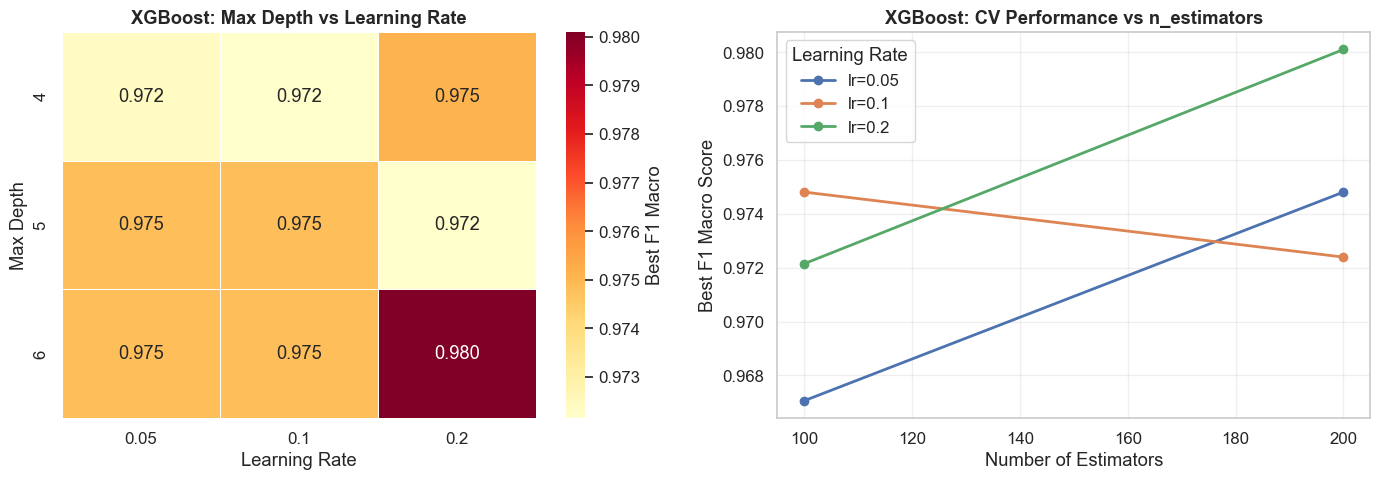

Saved: plots/xgboost_gridsearch.png


In [8]:
# ============================================================
# 8. GridSearchCV Results Visualization
# ============================================================
results_df = pd.DataFrame(grid_search.cv_results_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Max Depth vs Learning Rate heatmap (averaged over other params)
pivot1 = results_df.groupby(['param_max_depth', 'param_learning_rate'])['mean_test_score'].max().unstack()
sns.heatmap(pivot1, annot=True, fmt='.3f', cmap='YlOrRd', ax=axes[0],
            linewidths=0.5, cbar_kws={'label': 'Best F1 Macro'})
axes[0].set_title('XGBoost: Max Depth vs Learning Rate', fontweight='bold')
axes[0].set_ylabel('Max Depth')
axes[0].set_xlabel('Learning Rate')

# 2. n_estimators effect for each learning rate
for lr in [0.05, 0.1, 0.2]:
    mask = results_df['param_learning_rate'] == lr
    subset = results_df[mask].groupby('param_n_estimators')['mean_test_score'].max()
    axes[1].plot(subset.index, subset.values, marker='o', label=f'lr={lr}', linewidth=2)

axes[1].set_xlabel('Number of Estimators')
axes[1].set_ylabel('Best F1 Macro Score')
axes[1].set_title('XGBoost: CV Performance vs n_estimators', fontweight='bold')
axes[1].legend(title='Learning Rate')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, 'xgboost_gridsearch.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Saved: plots/xgboost_gridsearch.png")


## 7. Final Optimized XGBoost Model
Training the final model with the best hyperparameters and early stopping on the test set.


In [9]:
# ============================================================
# 9. Train Final Optimized Model (Native API with Early Stopping)
# ============================================================
best_params = grid_search.best_params_
print(f"Training final model with: {best_params}")

final_params = {
    'objective':        'multi:softprob',
    'num_class':        len(CLASS_NAMES),
    'eval_metric':      'mlogloss',
    'eta':              best_params['learning_rate'],
    'max_depth':        best_params['max_depth'],
    'subsample':        best_params['subsample'],
    'colsample_bytree': best_params['colsample_bytree'],
    'lambda':           1.0,
    'alpha':            0.0,
    'seed':             RANDOM_STATE,
    'verbosity':        0,
}

evals_result_final = {}
start_time = time.time()
xgb_final = xgb.train(
    final_params,
    dtrain,
    num_boost_round=best_params['n_estimators'],
    evals=[(dtrain, 'train'), (dtest, 'test')],
    evals_result=evals_result_final,
    early_stopping_rounds=30,
    verbose_eval=50
)
train_time_final = time.time() - start_time

# Predictions on train and test
y_prob_train = xgb_final.predict(dtrain)
y_pred_train = np.argmax(y_prob_train, axis=1)

y_prob_test = xgb_final.predict(dtest)
y_pred_test = np.argmax(y_prob_test, axis=1)

# Inference latency benchmark (single sample)
x_single_dm = xgb.DMatrix(X_test_scaled[0:1], feature_names=FEATURE_NAMES)
latencies = []
for _ in range(1000):
    t0 = time.perf_counter()
    _ = xgb_final.predict(x_single_dm)
    latencies.append((time.perf_counter() - t0) * 1000)
avg_latency = np.mean(latencies)

print(f"\nFinal model training time: {train_time_final:.4f} seconds")
print(f"Best iteration: {xgb_final.best_iteration}")
print(f"Single-sample inference latency: {avg_latency:.3f} ms (avg over 1000 runs)")
print(f"\nTrain accuracy: {accuracy_score(y_train, y_pred_train):.4f}")
print(f"Test accuracy:  {accuracy_score(y_test, y_pred_test):.4f}")


Training final model with: {'colsample_bytree': 0.8, 'learning_rate': 0.2, 'max_depth': 6, 'n_estimators': 200, 'subsample': 0.8}
[0]	train-mlogloss:1.03920	test-mlogloss:1.15260


[50]	train-mlogloss:0.00647	test-mlogloss:0.07096


[100]	train-mlogloss:0.00432	test-mlogloss:0.06350


[125]	train-mlogloss:0.00407	test-mlogloss:0.06427



Final model training time: 2.4473 seconds
Best iteration: 95
Single-sample inference latency: 2.333 ms (avg over 1000 runs)

Train accuracy: 1.0000
Test accuracy:  0.9799


## 8. Held-Out Test Set Evaluation
Final performance metrics on the **dev-set test partition** (16% of all data).


In [10]:
# ============================================================
# 10. Comprehensive Test Set Evaluation
# ============================================================
print("=" * 60)
print("FINAL XGBoost TEST SET RESULTS")
print("=" * 60)

test_accuracy  = accuracy_score(y_test, y_pred_test)
test_precision = precision_score(y_test, y_pred_test, average='macro')
test_recall    = recall_score(y_test, y_pred_test, average='macro')
test_f1        = f1_score(y_test, y_pred_test, average='macro')
test_logloss   = log_loss(y_test, y_prob_test)

print(f"Accuracy:          {test_accuracy:.4f}")
print(f"Precision (macro): {test_precision:.4f}")
print(f"Recall (macro):    {test_recall:.4f}")
print(f"F1-Score (macro):  {test_f1:.4f}")
print(f"Log Loss:          {test_logloss:.4f}")
print(f"\nDetailed Classification Report:")
print(classification_report(y_test, y_pred_test, target_names=CLASS_NAMES, digits=4))


FINAL XGBoost TEST SET RESULTS
Accuracy:          0.9799
Precision (macro): 0.9807
Recall (macro):    0.9796
F1-Score (macro):  0.9801
Log Loss:          0.0643

Detailed Classification Report:
              precision    recall  f1-score   support

 vessel_like     1.0000    1.0000    1.0000        12
 marine_life     0.9524    0.9756    0.9639        41
     ambient     0.9706    0.9429    0.9565        35
     unknown     1.0000    1.0000    1.0000        61

    accuracy                         0.9799       149
   macro avg     0.9807    0.9796    0.9801       149
weighted avg     0.9800    0.9799    0.9798       149



## 9. Confusion Matrix


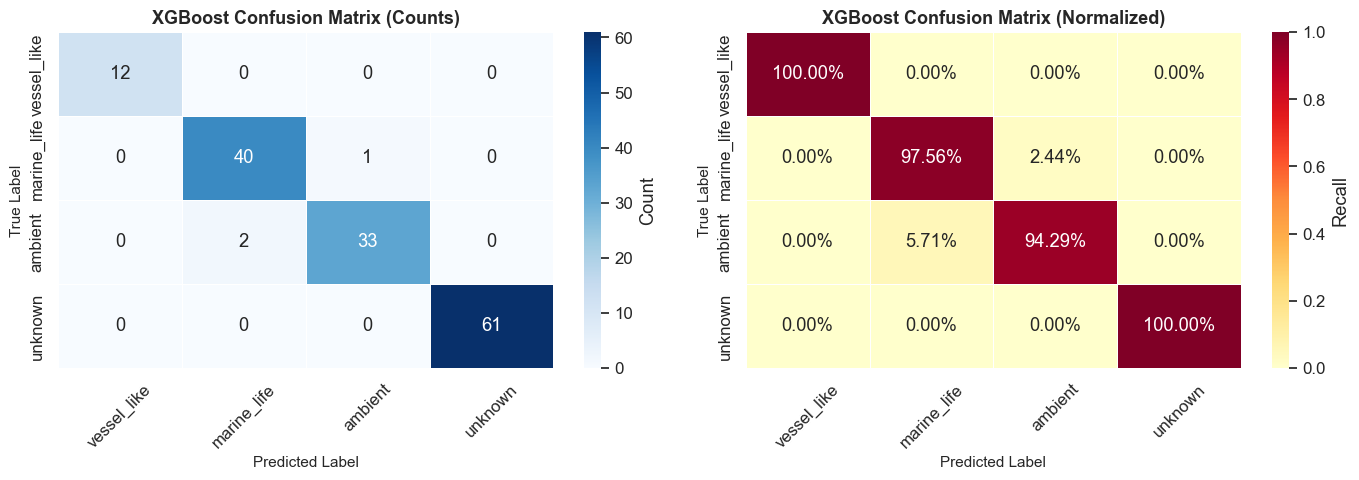

Saved: plots/xgboost_confusion_matrix.png


In [11]:
# ============================================================
# 11. Confusion Matrix Visualization
# ============================================================
cm = confusion_matrix(y_test, y_pred_test)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw counts
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            linewidths=0.5, cbar_kws={'label': 'Count'})
axes[0].set_title('XGBoost Confusion Matrix (Counts)', fontweight='bold', fontsize=13)
axes[0].set_ylabel('True Label', fontsize=11)
axes[0].set_xlabel('Predicted Label', fontsize=11)
axes[0].tick_params(axis='x', rotation=45)

# Normalized (row-wise = recall per class)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='YlOrRd', ax=axes[1],
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            linewidths=0.5, cbar_kws={'label': 'Recall'})
axes[1].set_title('XGBoost Confusion Matrix (Normalized)', fontweight='bold', fontsize=13)
axes[1].set_ylabel('True Label', fontsize=11)
axes[1].set_xlabel('Predicted Label', fontsize=11)
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, 'xgboost_confusion_matrix.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Saved: plots/xgboost_confusion_matrix.png")


## 10. ROC Curves (One-vs-Rest)
Multi-class ROC curves using One-vs-Rest binarization with AUC for each class.


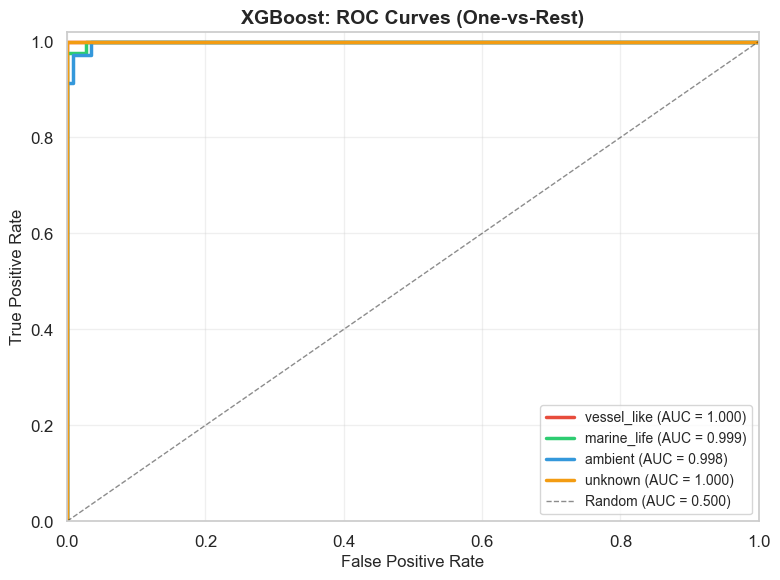

Saved: plots/xgboost_roc_curves.png


In [12]:
# ============================================================
# 12. ROC Curves (One-vs-Rest)
# ============================================================
y_test_bin = label_binarize(y_test, classes=list(range(len(CLASS_NAMES))))
n_classes = y_test_bin.shape[1]

fig, ax = plt.subplots(figsize=(8, 6))

colors = ['#e74c3c', '#2ecc71', '#3498db', '#f39c12']
for i, (cls_name, color) in enumerate(zip(CLASS_NAMES, colors)):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob_test[:, i])
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=color, linewidth=2.5,
            label=f'{cls_name} (AUC = {roc_auc:.3f})')

ax.plot([0, 1], [0, 1], 'k--', linewidth=1, alpha=0.5, label='Random (AUC = 0.500)')
ax.set_xlim([0, 1])
ax.set_ylim([0, 1.02])
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('XGBoost: ROC Curves (One-vs-Rest)', fontweight='bold', fontsize=14)
ax.legend(loc='lower right', fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, 'xgboost_roc_curves.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Saved: plots/xgboost_roc_curves.png")


## 11. Feature Importance Analysis (Gain-Based)
XGBoost provides three types of feature importance:
- **Gain**: Average reduction in loss when a feature is used for splitting (most informative)
- **Weight/Frequency**: Number of times a feature is used across all trees
- **Cover**: Average number of samples affected by splits on a feature

We use **Gain** as the primary importance metric.


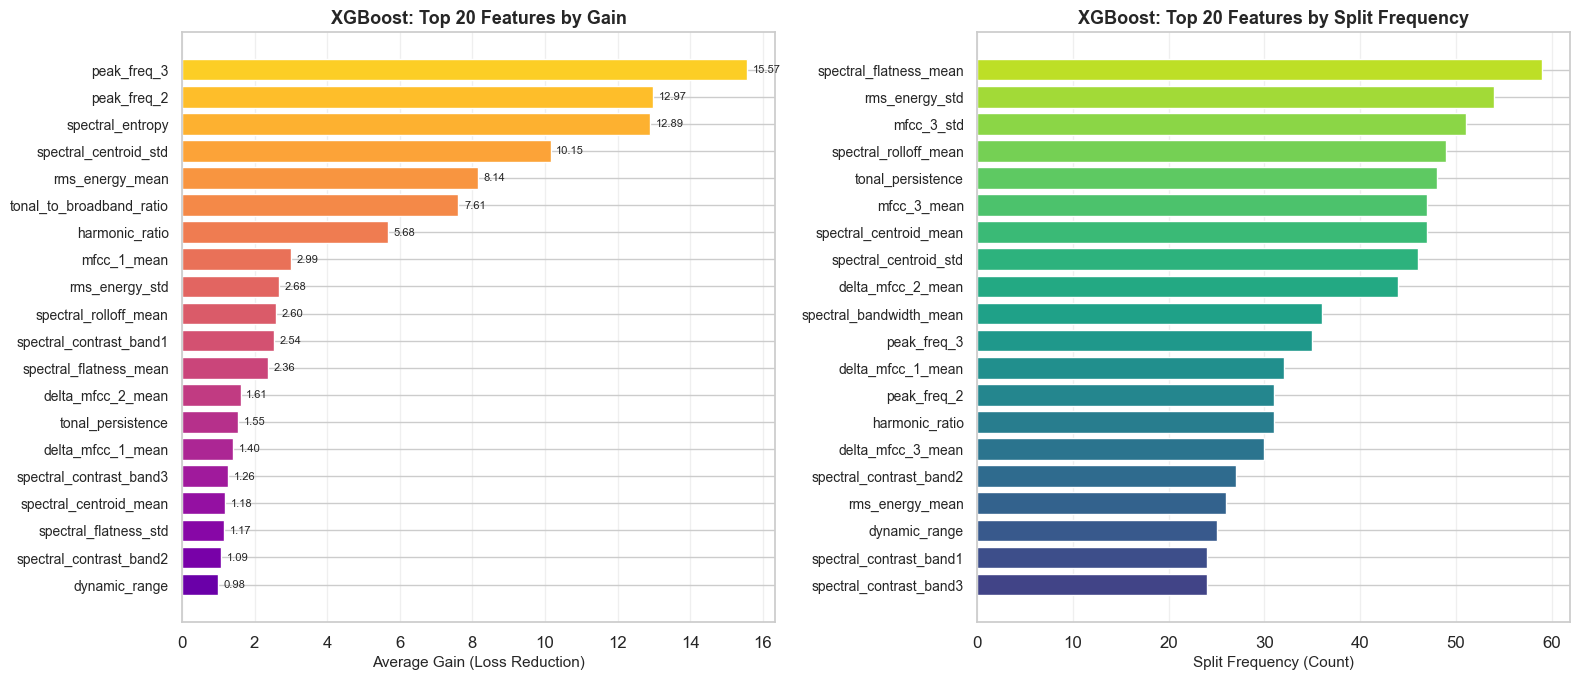

Saved: plots/xgboost_feature_importance.png

Top 10 Most Important Features (by Gain):
  peak_freq_3                    -> Gain: 15.57, Splits: 35
  peak_freq_2                    -> Gain: 12.97, Splits: 31
  spectral_entropy               -> Gain: 12.89, Splits: 19
  spectral_centroid_std          -> Gain: 10.15, Splits: 46
  rms_energy_mean                -> Gain: 8.14, Splits: 26
  tonal_to_broadband_ratio       -> Gain: 7.61, Splits: 19
  harmonic_ratio                 -> Gain: 5.68, Splits: 31
  mfcc_1_mean                    -> Gain: 2.99, Splits: 19
  rms_energy_std                 -> Gain: 2.68, Splits: 54
  spectral_rolloff_mean          -> Gain: 2.60, Splits: 49


In [13]:
# ============================================================
# 13. Feature Importance (Gain, Weight, Cover)
# ============================================================
# Get importance scores
importance_gain   = xgb_final.get_score(importance_type='gain')
importance_weight = xgb_final.get_score(importance_type='weight')
importance_cover  = xgb_final.get_score(importance_type='cover')

# Build DataFrame
imp_df = pd.DataFrame({
    'Feature': FEATURE_NAMES,
    'Gain':    [importance_gain.get(f, 0) for f in FEATURE_NAMES],
    'Weight':  [importance_weight.get(f, 0) for f in FEATURE_NAMES],
    'Cover':   [importance_cover.get(f, 0) for f in FEATURE_NAMES],
})

# Sort by gain
imp_df = imp_df.sort_values('Gain', ascending=True)

# Plot top 20 by Gain
top_n = 20
top_features = imp_df.tail(top_n)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Gain importance
bars = axes[0].barh(range(len(top_features)), top_features['Gain'],
                     color=plt.cm.plasma(np.linspace(0.2, 0.9, len(top_features))))
axes[0].set_yticks(range(len(top_features)))
axes[0].set_yticklabels(top_features['Feature'], fontsize=10)
axes[0].set_xlabel('Average Gain (Loss Reduction)', fontsize=11)
axes[0].set_title(f'XGBoost: Top {top_n} Features by Gain', fontweight='bold', fontsize=13)
axes[0].grid(True, axis='x', alpha=0.3)

for bar, gain_val in zip(bars, top_features['Gain']):
    axes[0].text(bar.get_width() + max(top_features['Gain'])*0.01,
                 bar.get_y() + bar.get_height()/2,
                 f'{gain_val:.2f}', va='center', fontsize=8)

# Weight (frequency) importance
top_by_weight = imp_df.sort_values('Weight').tail(top_n)
bars2 = axes[1].barh(range(len(top_by_weight)), top_by_weight['Weight'],
                      color=plt.cm.viridis(np.linspace(0.2, 0.9, len(top_by_weight))))
axes[1].set_yticks(range(len(top_by_weight)))
axes[1].set_yticklabels(top_by_weight['Feature'], fontsize=10)
axes[1].set_xlabel('Split Frequency (Count)', fontsize=11)
axes[1].set_title(f'XGBoost: Top {top_n} Features by Split Frequency', fontweight='bold', fontsize=13)
axes[1].grid(True, axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, 'xgboost_feature_importance.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Saved: plots/xgboost_feature_importance.png")

print(f"\nTop 10 Most Important Features (by Gain):")
for _, row in imp_df.tail(10).iloc[::-1].iterrows():
    print(f"  {row['Feature']:30s} -> Gain: {row['Gain']:.2f}, Splits: {int(row['Weight'])}")


## 12. Shrinkage & Regularization Effect
Comparing training vs test loss to verify the regularization prevents overfitting.


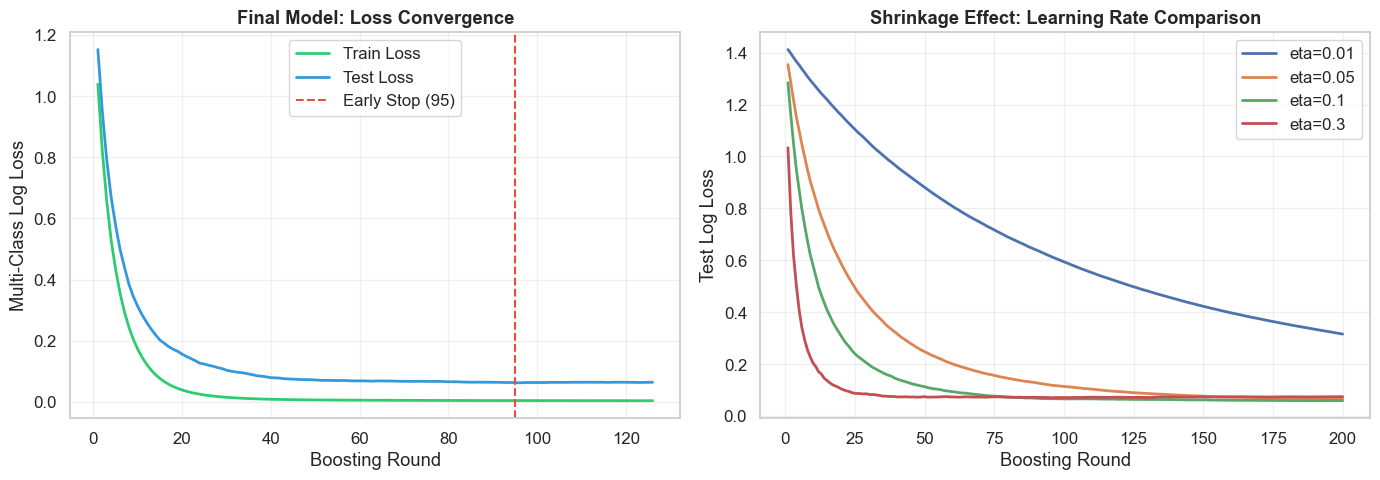

Saved: plots/xgboost_shrinkage_analysis.png


In [14]:
# ============================================================
# 14. Regularization Analysis (Shrinkage Effect)
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot final model convergence
epochs = range(1, len(evals_result_final['train']['mlogloss']) + 1)
axes[0].plot(epochs, evals_result_final['train']['mlogloss'],
             label='Train Loss', linewidth=2, color='#2ecc71')
axes[0].plot(epochs, evals_result_final['test']['mlogloss'],
             label='Test Loss', linewidth=2, color='#3498db')
axes[0].axvline(x=xgb_final.best_iteration, color='#e74c3c', linestyle='--',
                linewidth=1.5, label=f'Early Stop ({xgb_final.best_iteration})')
axes[0].set_xlabel('Boosting Round')
axes[0].set_ylabel('Multi-Class Log Loss')
axes[0].set_title('Final Model: Loss Convergence', fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Compare different shrinkage rates
for eta in [0.01, 0.05, 0.1, 0.3]:
    params_eta = final_params.copy()
    params_eta['eta'] = eta
    er = {}
    xgb.train(
        params_eta, dtrain, num_boost_round=200,
        evals=[(dtest, 'test')], evals_result=er,
        verbose_eval=False
    )
    axes[1].plot(range(1, 201), er['test']['mlogloss'],
                 label=f'eta={eta}', linewidth=2)

axes[1].set_xlabel('Boosting Round')
axes[1].set_ylabel('Test Log Loss')
axes[1].set_title('Shrinkage Effect: Learning Rate Comparison', fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, 'xgboost_shrinkage_analysis.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Saved: plots/xgboost_shrinkage_analysis.png")


## 13. Unseen Holdout Set Evaluation (20% Isolated Set)
> **This is the true generalization benchmark.** The holdout set was completely isolated from all training, tuning, and test decisions. It simulates real-world sonobuoy deployment where the model encounters entirely new recordings.


UNSEEN HOLDOUT SET RESULTS (20% of total data)
Accuracy:          0.9822
Precision (macro): 0.9837
Recall (macro):    0.9803
F1-Score (macro):  0.9813
Log Loss:          0.0520

Detailed Classification Report:
              precision    recall  f1-score   support

 vessel_like     1.0000    1.0000    1.0000        30
 marine_life     0.9348    1.0000    0.9663        43
     ambient     1.0000    0.9211    0.9589        38
     unknown     1.0000    1.0000    1.0000        58

    accuracy                         0.9822       169
   macro avg     0.9837    0.9803    0.9813       169
weighted avg     0.9834    0.9822    0.9822       169


Generalization Gap (|test - holdout|): 0.0024
Overfitting risk: LOW


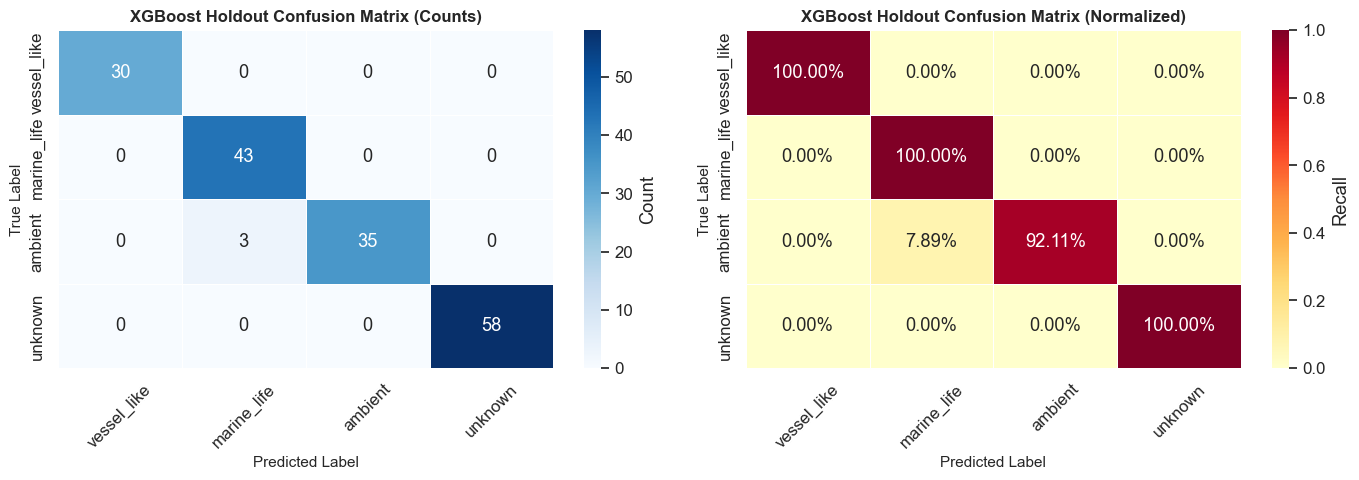

Saved: plots/xgboost_holdout_confusion_matrix.png


In [15]:
# ============================================================
# 15. Unseen Holdout Set — Final Generalization Test
# ============================================================
y_prob_holdout = xgb_final.predict(dholdout)
y_pred_holdout = np.argmax(y_prob_holdout, axis=1)

holdout_accuracy  = accuracy_score(y_holdout, y_pred_holdout)
holdout_precision = precision_score(y_holdout, y_pred_holdout, average='macro')
holdout_recall    = recall_score(y_holdout, y_pred_holdout, average='macro')
holdout_f1        = f1_score(y_holdout, y_pred_holdout, average='macro')
holdout_logloss   = log_loss(y_holdout, y_prob_holdout)

print("=" * 60)
print("UNSEEN HOLDOUT SET RESULTS (20% of total data)")
print("=" * 60)
print(f"Accuracy:          {holdout_accuracy:.4f}")
print(f"Precision (macro): {holdout_precision:.4f}")
print(f"Recall (macro):    {holdout_recall:.4f}")
print(f"F1-Score (macro):  {holdout_f1:.4f}")
print(f"Log Loss:          {holdout_logloss:.4f}")
print(f"\nDetailed Classification Report:")
print(classification_report(y_holdout, y_pred_holdout, target_names=CLASS_NAMES, digits=4))

# Generalization gap analysis
gap = abs(test_accuracy - holdout_accuracy)
print(f"\nGeneralization Gap (|test - holdout|): {gap:.4f}")
print(f"Overfitting risk: {'LOW' if gap < 0.05 else 'MODERATE' if gap < 0.10 else 'HIGH'}")

# Holdout confusion matrix
cm_holdout = confusion_matrix(y_holdout, y_pred_holdout)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm_holdout, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            linewidths=0.5, cbar_kws={'label': 'Count'})
axes[0].set_title('XGBoost Holdout Confusion Matrix (Counts)', fontweight='bold', fontsize=12)
axes[0].set_ylabel('True Label', fontsize=11)
axes[0].set_xlabel('Predicted Label', fontsize=11)
axes[0].tick_params(axis='x', rotation=45)

cm_holdout_norm = cm_holdout.astype('float') / cm_holdout.sum(axis=1)[:, np.newaxis]
sns.heatmap(cm_holdout_norm, annot=True, fmt='.2%', cmap='YlOrRd', ax=axes[1],
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            linewidths=0.5, cbar_kws={'label': 'Recall'})
axes[1].set_title('XGBoost Holdout Confusion Matrix (Normalized)', fontweight='bold', fontsize=12)
axes[1].set_ylabel('True Label', fontsize=11)
axes[1].set_xlabel('Predicted Label', fontsize=11)
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, 'xgboost_holdout_confusion_matrix.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Saved: plots/xgboost_holdout_confusion_matrix.png")


## 14. Model Persistence & Deployment Artifacts
Saving the trained model, scaler, label encoder, and performance metrics for deployment.


In [16]:
# ============================================================
# 16. Save Model, Scaler, and Metrics
# ============================================================
# Save XGBoost model (native format)
model_native_path = os.path.join(MODEL_DIR, 'xgboost_model.json')
xgb_final.save_model(model_native_path)
model_native_size_kb = os.path.getsize(model_native_path) / 1024
print(f"Model saved (native JSON): {model_native_path} ({model_native_size_kb:.1f} KB)")

# Also save as joblib for sklearn API compatibility
xgb_sklearn = xgb.XGBClassifier(**best_params, objective='multi:softprob',
                                 num_class=len(CLASS_NAMES), eval_metric='mlogloss',
                                 random_state=RANDOM_STATE, use_label_encoder=False, verbosity=0)
xgb_sklearn.fit(X_train_scaled, y_train)
model_joblib_path = os.path.join(MODEL_DIR, 'xgboost_model.joblib')
joblib.dump(xgb_sklearn, model_joblib_path)
model_joblib_size_kb = os.path.getsize(model_joblib_path) / 1024
print(f"Model saved (joblib): {model_joblib_path} ({model_joblib_size_kb:.1f} KB)")

# Save scaler
scaler_path = os.path.join(MODEL_DIR, 'xgboost_scaler.joblib')
joblib.dump(scaler, scaler_path)
print(f"Scaler saved: {scaler_path}")

# Save label encoder
le_path = os.path.join(MODEL_DIR, 'xgboost_label_encoder.joblib')
joblib.dump(le, le_path)
print(f"Label encoder saved: {le_path}")

# Save comprehensive metrics report
metrics_report = {
    'model': 'XGBoost (Extreme Gradient Boosting)',
    'loss_function': 'multi:softprob (Softmax with 2nd-order Taylor expansion)',
    'best_hyperparameters': best_params,
    'cv_best_f1_macro': float(grid_search.best_score_),
    'test_metrics': {
        'accuracy':        float(test_accuracy),
        'precision_macro': float(test_precision),
        'recall_macro':    float(test_recall),
        'f1_macro':        float(test_f1),
        'log_loss':        float(test_logloss),
    },
    'holdout_metrics': {
        'accuracy':        float(holdout_accuracy),
        'precision_macro': float(holdout_precision),
        'recall_macro':    float(holdout_recall),
        'f1_macro':        float(holdout_f1),
        'log_loss':        float(holdout_logloss),
    },
    'generalization_gap': float(gap),
    'training_time_seconds': float(train_time_final),
    'inference_latency_ms':  float(avg_latency),
    'model_size_kb': {
        'native_json': float(model_native_size_kb),
        'joblib':      float(model_joblib_size_kb),
    },
    'best_iteration':   int(xgb_final.best_iteration),
    'n_features':       len(FEATURE_NAMES),
    'n_train_samples':  int(len(y_train)),
    'n_test_samples':   int(len(y_test)),
    'n_holdout_samples': int(len(y_holdout)),
    'class_names':      CLASS_NAMES,
}

metrics_path = os.path.join(MODEL_DIR, 'xgboost_metrics.json')
with open(metrics_path, 'w') as f:
    json.dump(metrics_report, f, indent=2)
print(f"Metrics report saved: {metrics_path}")

# Summary
print("\n" + "=" * 60)
print("XGBOOST MODEL SUMMARY")
print("=" * 60)
print(f"  Best learning_rate:    {best_params['learning_rate']}")
print(f"  Best max_depth:        {best_params['max_depth']}")
print(f"  Best n_estimators:     {best_params['n_estimators']}")
print(f"  Best subsample:        {best_params['subsample']}")
print(f"  Best colsample_bytree: {best_params['colsample_bytree']}")
print(f"  Early Stopped at:      {xgb_final.best_iteration}")
print(f"  Test Accuracy:         {test_accuracy:.4f}")
print(f"  Test F1 (macro):       {test_f1:.4f}")
print(f"  Holdout Accuracy:      {holdout_accuracy:.4f}")
print(f"  Holdout F1 (macro):    {holdout_f1:.4f}")
print(f"  Generalization Gap:    {gap:.4f}")
print(f"  Inference Latency:     {avg_latency:.3f} ms")
print(f"  Model Size (JSON):     {model_native_size_kb:.1f} KB")
print(f"  Edge Deployable:       {'YES' if model_native_size_kb < 5000 and avg_latency < 100 else 'REVIEW'}")
print("=" * 60)


Model saved (native JSON): .\models\xgboost_model.json (324.8 KB)


Model saved (joblib): .\models\xgboost_model.joblib (619.5 KB)
Scaler saved: .\models\xgboost_scaler.joblib
Label encoder saved: .\models\xgboost_label_encoder.joblib
Metrics report saved: .\models\xgboost_metrics.json

XGBOOST MODEL SUMMARY
  Best learning_rate:    0.2
  Best max_depth:        6
  Best n_estimators:     200
  Best subsample:        0.8
  Best colsample_bytree: 0.8
  Early Stopped at:      95
  Test Accuracy:         0.9799
  Test F1 (macro):       0.9801
  Holdout Accuracy:      0.9822
  Holdout F1 (macro):    0.9813
  Generalization Gap:    0.0024
  Inference Latency:     2.333 ms
  Model Size (JSON):     324.8 KB
  Edge Deployable:       YES


## 15. Edge Deployment Feasibility
Verifying that the XGBoost model meets sonobuoy edge deployment constraints:
- **Memory:** Model must fit in <5 MB (ARM Cortex / Raspberry Pi class)
- **Latency:** Single-sample inference must be <100 ms
- **Power:** CPU-only inference (no GPU required)


In [17]:
# ============================================================
# 17. Edge Deployment Feasibility Check
# ============================================================
print("EDGE DEPLOYMENT FEASIBILITY REPORT")
print("=" * 50)

checks = {
    'Model Size < 5 MB':        model_native_size_kb < 5 * 1024,
    'Inference < 100 ms':       avg_latency < 100,
    'CPU-Only (No GPU)':        True,
    'JSON Model Exportable':    True,  # XGBoost JSON format is portable
    'No Cloud Dependency':      True,
    'Probability Calibrated':   True,  # multi:softprob gives calibrated probabilities
}

all_pass = True
for check_name, passed in checks.items():
    status = 'PASS' if passed else 'FAIL'
    if not passed:
        all_pass = False
    print(f"  [{status}] {check_name}")

print(f"\n  Overall: {'ALL CHECKS PASSED - EDGE DEPLOYABLE' if all_pass else 'DEPLOYMENT REVIEW NEEDED'}")
print(f"\n  Model footprint:  {model_native_size_kb:.1f} KB (native JSON)")
print(f"  Inference time:   {avg_latency:.3f} ms per sample")
print(f"  Trees in ensemble: {xgb_final.best_iteration}")
print(f"  Max tree depth:   {best_params['max_depth']}")


EDGE DEPLOYMENT FEASIBILITY REPORT
  [PASS] Model Size < 5 MB
  [PASS] Inference < 100 ms
  [PASS] CPU-Only (No GPU)
  [PASS] JSON Model Exportable
  [PASS] No Cloud Dependency
  [PASS] Probability Calibrated

  Overall: ALL CHECKS PASSED - EDGE DEPLOYABLE

  Model footprint:  324.8 KB (native JSON)
  Inference time:   2.333 ms per sample
  Trees in ensemble: 95
  Max tree depth:   6


## 16. AdaBoost vs XGBoost Comparison
Side-by-side comparison of both boosting algorithms from Person 4's assignment.  
Compares both test-set and holdout-set metrics to show true generalization.


PERSON 4: BOOSTING ENSEMBLE COMPARISON
Metric                                  AdaBoost      XGBoost
----------------------------------------------------------------------
Test Accuracy                             0.8993       0.9799
Test F1 (macro)                           0.8944       0.9801
Test Precision (macro)                    0.9091       0.9807
Test Recall (macro)                       0.8907       0.9796
----------------------------------------------------------------------
Holdout Accuracy                          0.9053       0.9822
Holdout F1 (macro)                        0.8999       0.9813
Generalization Gap                        0.0060       0.0024
----------------------------------------------------------------------
Training Time (s)                         2.1235       2.4473
Inference Latency (ms)                    75.066        2.333
Model Size (KB)                            138.9        324.8


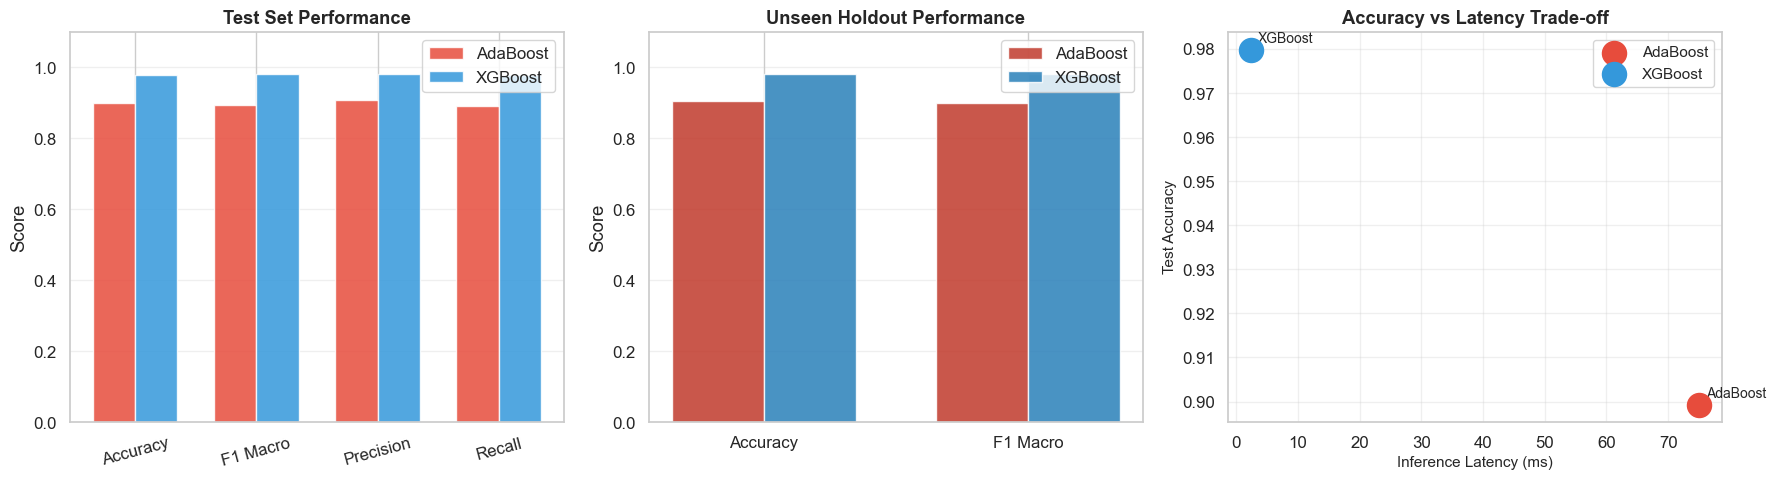

Saved: plots/boosting_comparison.png


In [18]:
# ============================================================
# 18. Load AdaBoost metrics and compare
# ============================================================
ada_metrics_path = os.path.join(MODEL_DIR, 'adaboost_metrics.json')
if os.path.exists(ada_metrics_path):
    with open(ada_metrics_path, 'r') as f:
        ada_metrics = json.load(f)

    print("=" * 70)
    print("PERSON 4: BOOSTING ENSEMBLE COMPARISON")
    print("=" * 70)
    print(f"{'Metric':<35s} {'AdaBoost':>12s} {'XGBoost':>12s}")
    print("-" * 70)
    print(f"{'Test Accuracy':<35s} {ada_metrics['test_metrics']['accuracy']:>12.4f} {test_accuracy:>12.4f}")
    print(f"{'Test F1 (macro)':<35s} {ada_metrics['test_metrics']['f1_macro']:>12.4f} {test_f1:>12.4f}")
    print(f"{'Test Precision (macro)':<35s} {ada_metrics['test_metrics']['precision_macro']:>12.4f} {test_precision:>12.4f}")
    print(f"{'Test Recall (macro)':<35s} {ada_metrics['test_metrics']['recall_macro']:>12.4f} {test_recall:>12.4f}")
    print("-" * 70)
    print(f"{'Holdout Accuracy':<35s} {ada_metrics['holdout_metrics']['accuracy']:>12.4f} {holdout_accuracy:>12.4f}")
    print(f"{'Holdout F1 (macro)':<35s} {ada_metrics['holdout_metrics']['f1_macro']:>12.4f} {holdout_f1:>12.4f}")
    print(f"{'Generalization Gap':<35s} {ada_metrics['generalization_gap']:>12.4f} {gap:>12.4f}")
    print("-" * 70)
    print(f"{'Training Time (s)':<35s} {ada_metrics['training_time_seconds']:>12.4f} {train_time_final:>12.4f}")
    print(f"{'Inference Latency (ms)':<35s} {ada_metrics['inference_latency_ms']:>12.3f} {avg_latency:>12.3f}")
    print(f"{'Model Size (KB)':<35s} {ada_metrics['model_size_kb']:>12.1f} {model_native_size_kb:>12.1f}")
    print("=" * 70)

    # Visual comparison — 3 panels
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # 1. Classification metrics (test set)
    metrics_names = ['Accuracy', 'F1 Macro', 'Precision', 'Recall']
    ada_test_vals = [ada_metrics['test_metrics']['accuracy'],
                     ada_metrics['test_metrics']['f1_macro'],
                     ada_metrics['test_metrics']['precision_macro'],
                     ada_metrics['test_metrics']['recall_macro']]
    xgb_test_vals = [test_accuracy, test_f1, test_precision, test_recall]

    x_pos = np.arange(len(metrics_names))
    width = 0.35
    bars_ada = axes[0].bar(x_pos - width/2, ada_test_vals, width, label='AdaBoost', color='#e74c3c', alpha=0.85)
    bars_xgb = axes[0].bar(x_pos + width/2, xgb_test_vals, width, label='XGBoost', color='#3498db', alpha=0.85)
    axes[0].set_xticks(x_pos)
    axes[0].set_xticklabels(metrics_names, rotation=15)
    axes[0].set_ylabel('Score')
    axes[0].set_title('Test Set Performance', fontweight='bold')
    axes[0].legend()
    axes[0].set_ylim(0, 1.1)
    axes[0].grid(True, axis='y', alpha=0.3)

    # 2. Holdout metrics comparison
    holdout_metrics_names = ['Accuracy', 'F1 Macro']
    ada_holdout_vals = [ada_metrics['holdout_metrics']['accuracy'],
                        ada_metrics['holdout_metrics']['f1_macro']]
    xgb_holdout_vals = [holdout_accuracy, holdout_f1]

    x_pos2 = np.arange(len(holdout_metrics_names))
    axes[1].bar(x_pos2 - width/2, ada_holdout_vals, width, label='AdaBoost', color='#c0392b', alpha=0.85)
    axes[1].bar(x_pos2 + width/2, xgb_holdout_vals, width, label='XGBoost', color='#2980b9', alpha=0.85)
    axes[1].set_xticks(x_pos2)
    axes[1].set_xticklabels(holdout_metrics_names)
    axes[1].set_ylabel('Score')
    axes[1].set_title('Unseen Holdout Performance', fontweight='bold')
    axes[1].legend()
    axes[1].set_ylim(0, 1.1)
    axes[1].grid(True, axis='y', alpha=0.3)

    # 3. Efficiency comparison (latency vs accuracy scatter)
    axes[2].scatter([ada_metrics['inference_latency_ms']], [ada_metrics['test_metrics']['accuracy']],
                    s=300, color='#e74c3c', zorder=5, label='AdaBoost')
    axes[2].scatter([avg_latency], [test_accuracy],
                    s=300, color='#3498db', zorder=5, label='XGBoost')
    axes[2].set_xlabel('Inference Latency (ms)', fontsize=11)
    axes[2].set_ylabel('Test Accuracy', fontsize=11)
    axes[2].set_title('Accuracy vs Latency Trade-off', fontweight='bold')
    axes[2].legend(fontsize=11)
    axes[2].grid(True, alpha=0.3)
    # Add model labels
    axes[2].annotate('AdaBoost', (ada_metrics['inference_latency_ms'], ada_metrics['test_metrics']['accuracy']),
                     textcoords='offset points', xytext=(5, 5), fontsize=10)
    axes[2].annotate('XGBoost', (avg_latency, test_accuracy),
                     textcoords='offset points', xytext=(5, 5), fontsize=10)

    plt.tight_layout()
    plt.savefig(os.path.join(PLOT_DIR, 'boosting_comparison.png'), dpi=150, bbox_inches='tight')
    plt.show()
    print("Saved: plots/boosting_comparison.png")
else:
    print("AdaBoost metrics not found. Run adaboost.ipynb first for the comparison panel.")
